# 02 · Baselines B0 / B1 / B2

Created by `scripts/run_agent2_baseline.py` (Step 2). Shows the **best score found so far** after each trial, for each method.

B2 (static Optuna TPE) is the main baseline the adaptive method must beat.

In [1]:
import json, ast, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from c2_automl.config import OUTPUT_DIR
from c2_automl.io.dummy_c1 import load_c1_output, load_split

# Validated light palette (same colours as the dashboard)
FAMILY_COLORS = {"random_forest": "#2a78d6", "xgboost": "#eb6834", "lightgbm": "#1baf7a",
                 "catboost": "#eda100", "logistic_regression": "#e87ba4", "ridge": "#008300"}
ROUND_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#184f95", 4: "#0d366b"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
                     "font.size": 10, "lines.linewidth": 2})

In [2]:
DATASET = "diabetes"

files = sorted(glob.glob(str(OUTPUT_DIR / DATASET / f"{DATASET}_*_trials.parquet")))
runs = {}
for f in files:
    df = pd.read_parquet(f)
    runs[df["run_id"].iloc[0]] = df
summary = pd.DataFrame([{"run_id": r, "method": d["method"].iloc[0], "trials": len(d),
                         "best": d["mean_val"].max()} for r, d in runs.items()])
summary

,run_id,method,trials,best
0,diabetes_defaults_20261016_165857,defaults,5,0.833414
1,diabetes_defaults_20261016_171219,defaults,5,0.833414
2,diabetes_random_20261016_165902,random,60,0.849128
3,diabetes_random_20261016_171224,random,60,0.849128
4,diabetes_tpe_20261016_165945,tpe,60,0.849128
5,diabetes_tpe_20261016_171307,tpe,60,0.849128


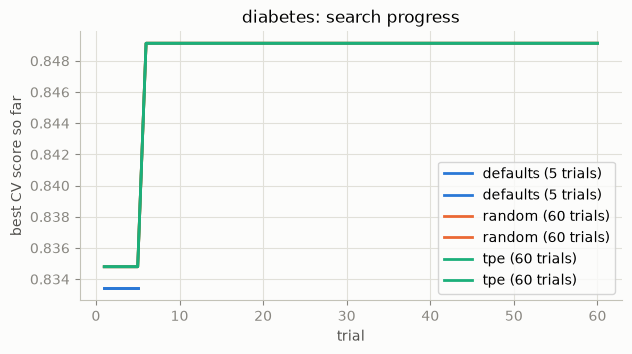

In [3]:
METHOD_COLORS = {"defaults": "#2a78d6", "random": "#eb6834", "tpe": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 3.5))
for run_id, d in runs.items():
    method = d["method"].iloc[0]
    best_so_far = d["mean_val"].fillna(0).cummax().values
    ax.plot(range(1, len(best_so_far) + 1), best_so_far, color=METHOD_COLORS.get(method, "#898781"),
            label=f"{method} ({len(d)} trials)")
ax.set_xlabel("trial"); ax.set_ylabel("best CV score so far"); ax.legend(); ax.set_title(f"{DATASET}: search progress")
plt.show()

> Trials run family by family, so the curve jumps when a stronger family starts. Compare the **end points** at the same trial budget.